# Phase retrieval using calibrated IL1 changes

Four **256 × 256** fixed-camera Gaussian intensity images constrain one complex exit wave. The ideal microscope uses the companion TOML configuration from the calibration examples. The smiley is encoded as a visible phase object; see [README.md](README.md) for the assumptions and method.

The saved figures are ready to use. The optional final cell regenerates all results.

**Sample and sampling clarification:** the current retrieval uses a phase-remapped version of the smiley, not the original function’s complex transmission. It uses 2,304 Gaussians for both synthetic data and inversion. The reported reconstruction error is not a Gaussian-basis convergence test. The original smiley notebook’s circular-wave settings give 246,301 Gaussians. `figures/smiley_function_amplitude_phase_256.png` shows the unmodified function.

Detector images: (4, 256, 256) · pixel pitch: 55.0 µm


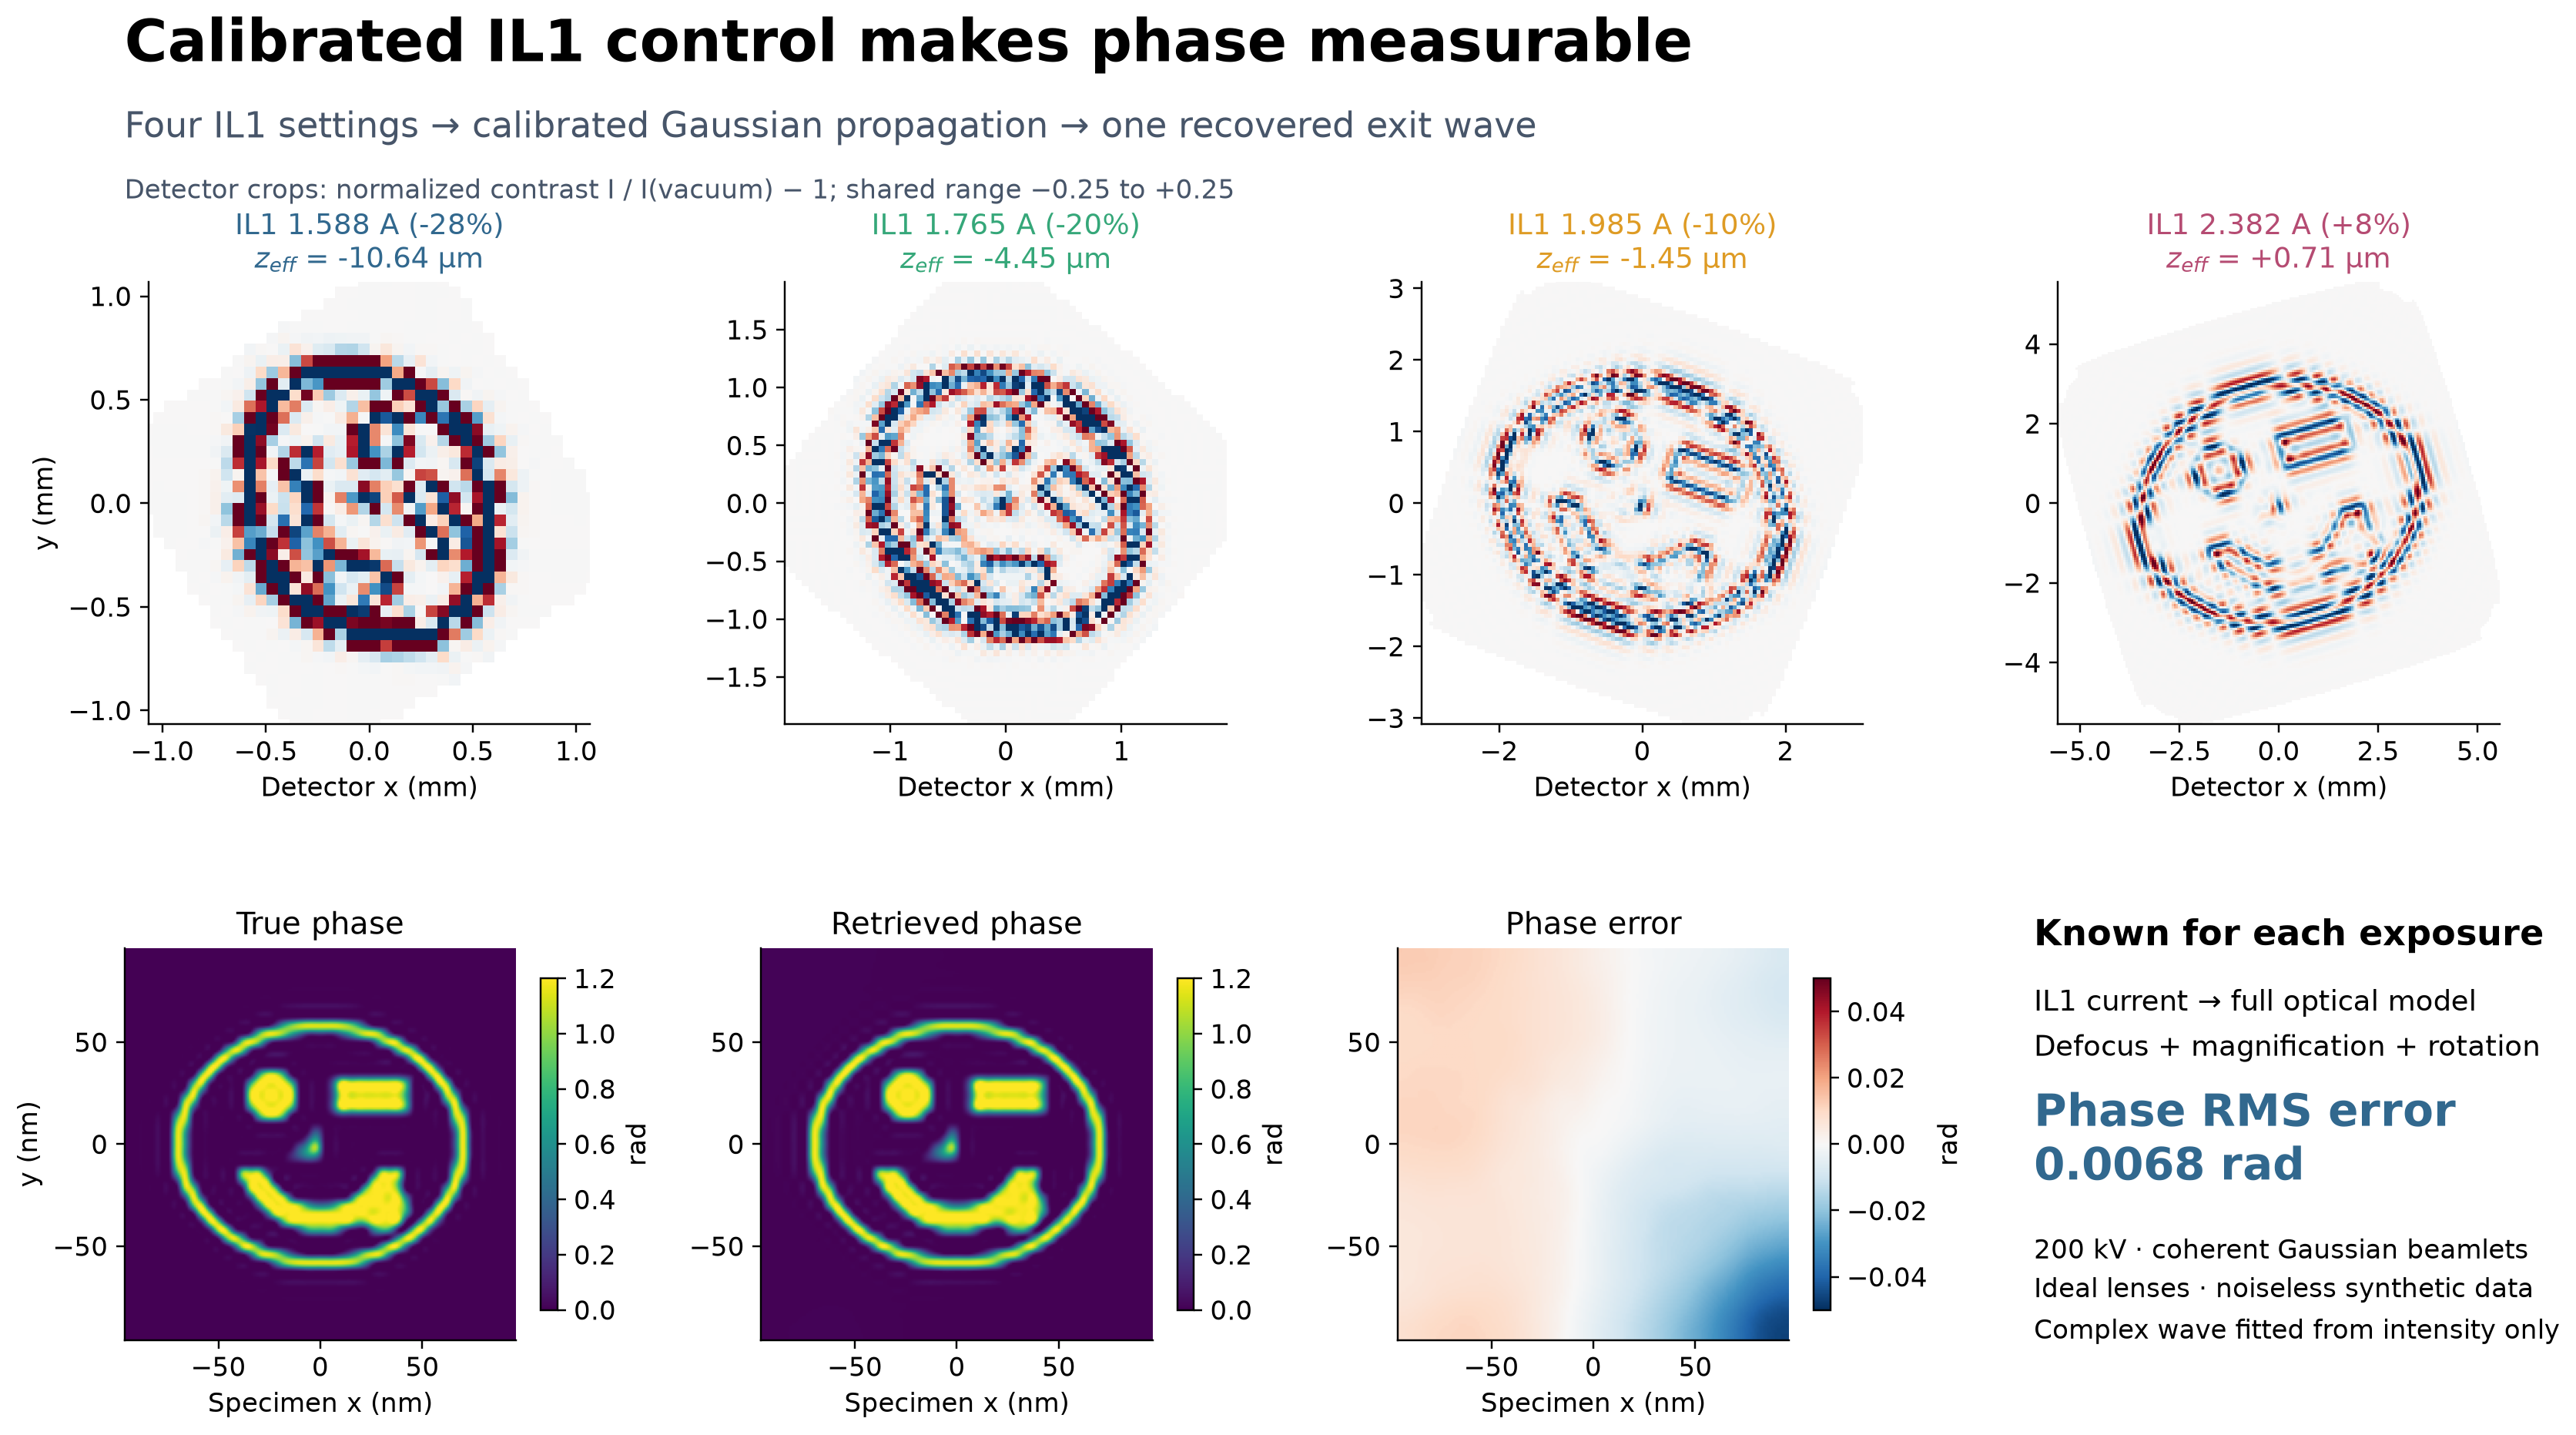

In [1]:
from pathlib import Path
import json
import numpy as np
from IPython.display import Image, display

repo = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'src/temgym_core').is_dir())
folder = repo / 'examples/phase_retrieval_demonstration'
data = np.load(folder / 'dataset.npz')
calibration = json.loads((folder / 'calibration.json').read_text())
assert data['intensities'].shape == (4, 256, 256)
print('Detector images:', data['intensities'].shape, '· pixel pitch:', float(data['detector_pitch_m'])*1e6, 'µm')
display(Image(filename=str(folder / 'figures/00_slide_overview.png')))

## Calibrated optical settings

Only IL1 changes. The detector stays fixed. Effective defocus is the signed specimen-equivalent propagation distance $z_{eff}=\mathrm{tr}(A^{-1}B)/2$. The full Gaussian propagation, including changing magnification and magnetic rotation, supplies the inverse operators.

The ray diagrams mark the **objective image plane**, real intermediate images, and the **final image plane** relative to the fixed detector. The arrow shows detector minus final-image position; this is distinct from the specimen-equivalent defocus above. Each row uses common physical axes across settings. The companion plot shows every lens's specimen-conjugate plane, found from $B + dD = 0$ after that lens: triangles mark virtual images, and crosses mark extrapolated planes intercepted by a downstream lens.

IL1 (A)   change   z_eff (µm)     M       rotation (deg)
1.588088  -28%     -10.642      9701    -56.28
1.764542  -20%      -4.448     17351    -40.20
1.985110  -10%      -1.452     28047    -20.10
2.382132  +8%      +0.707     50469    +16.08


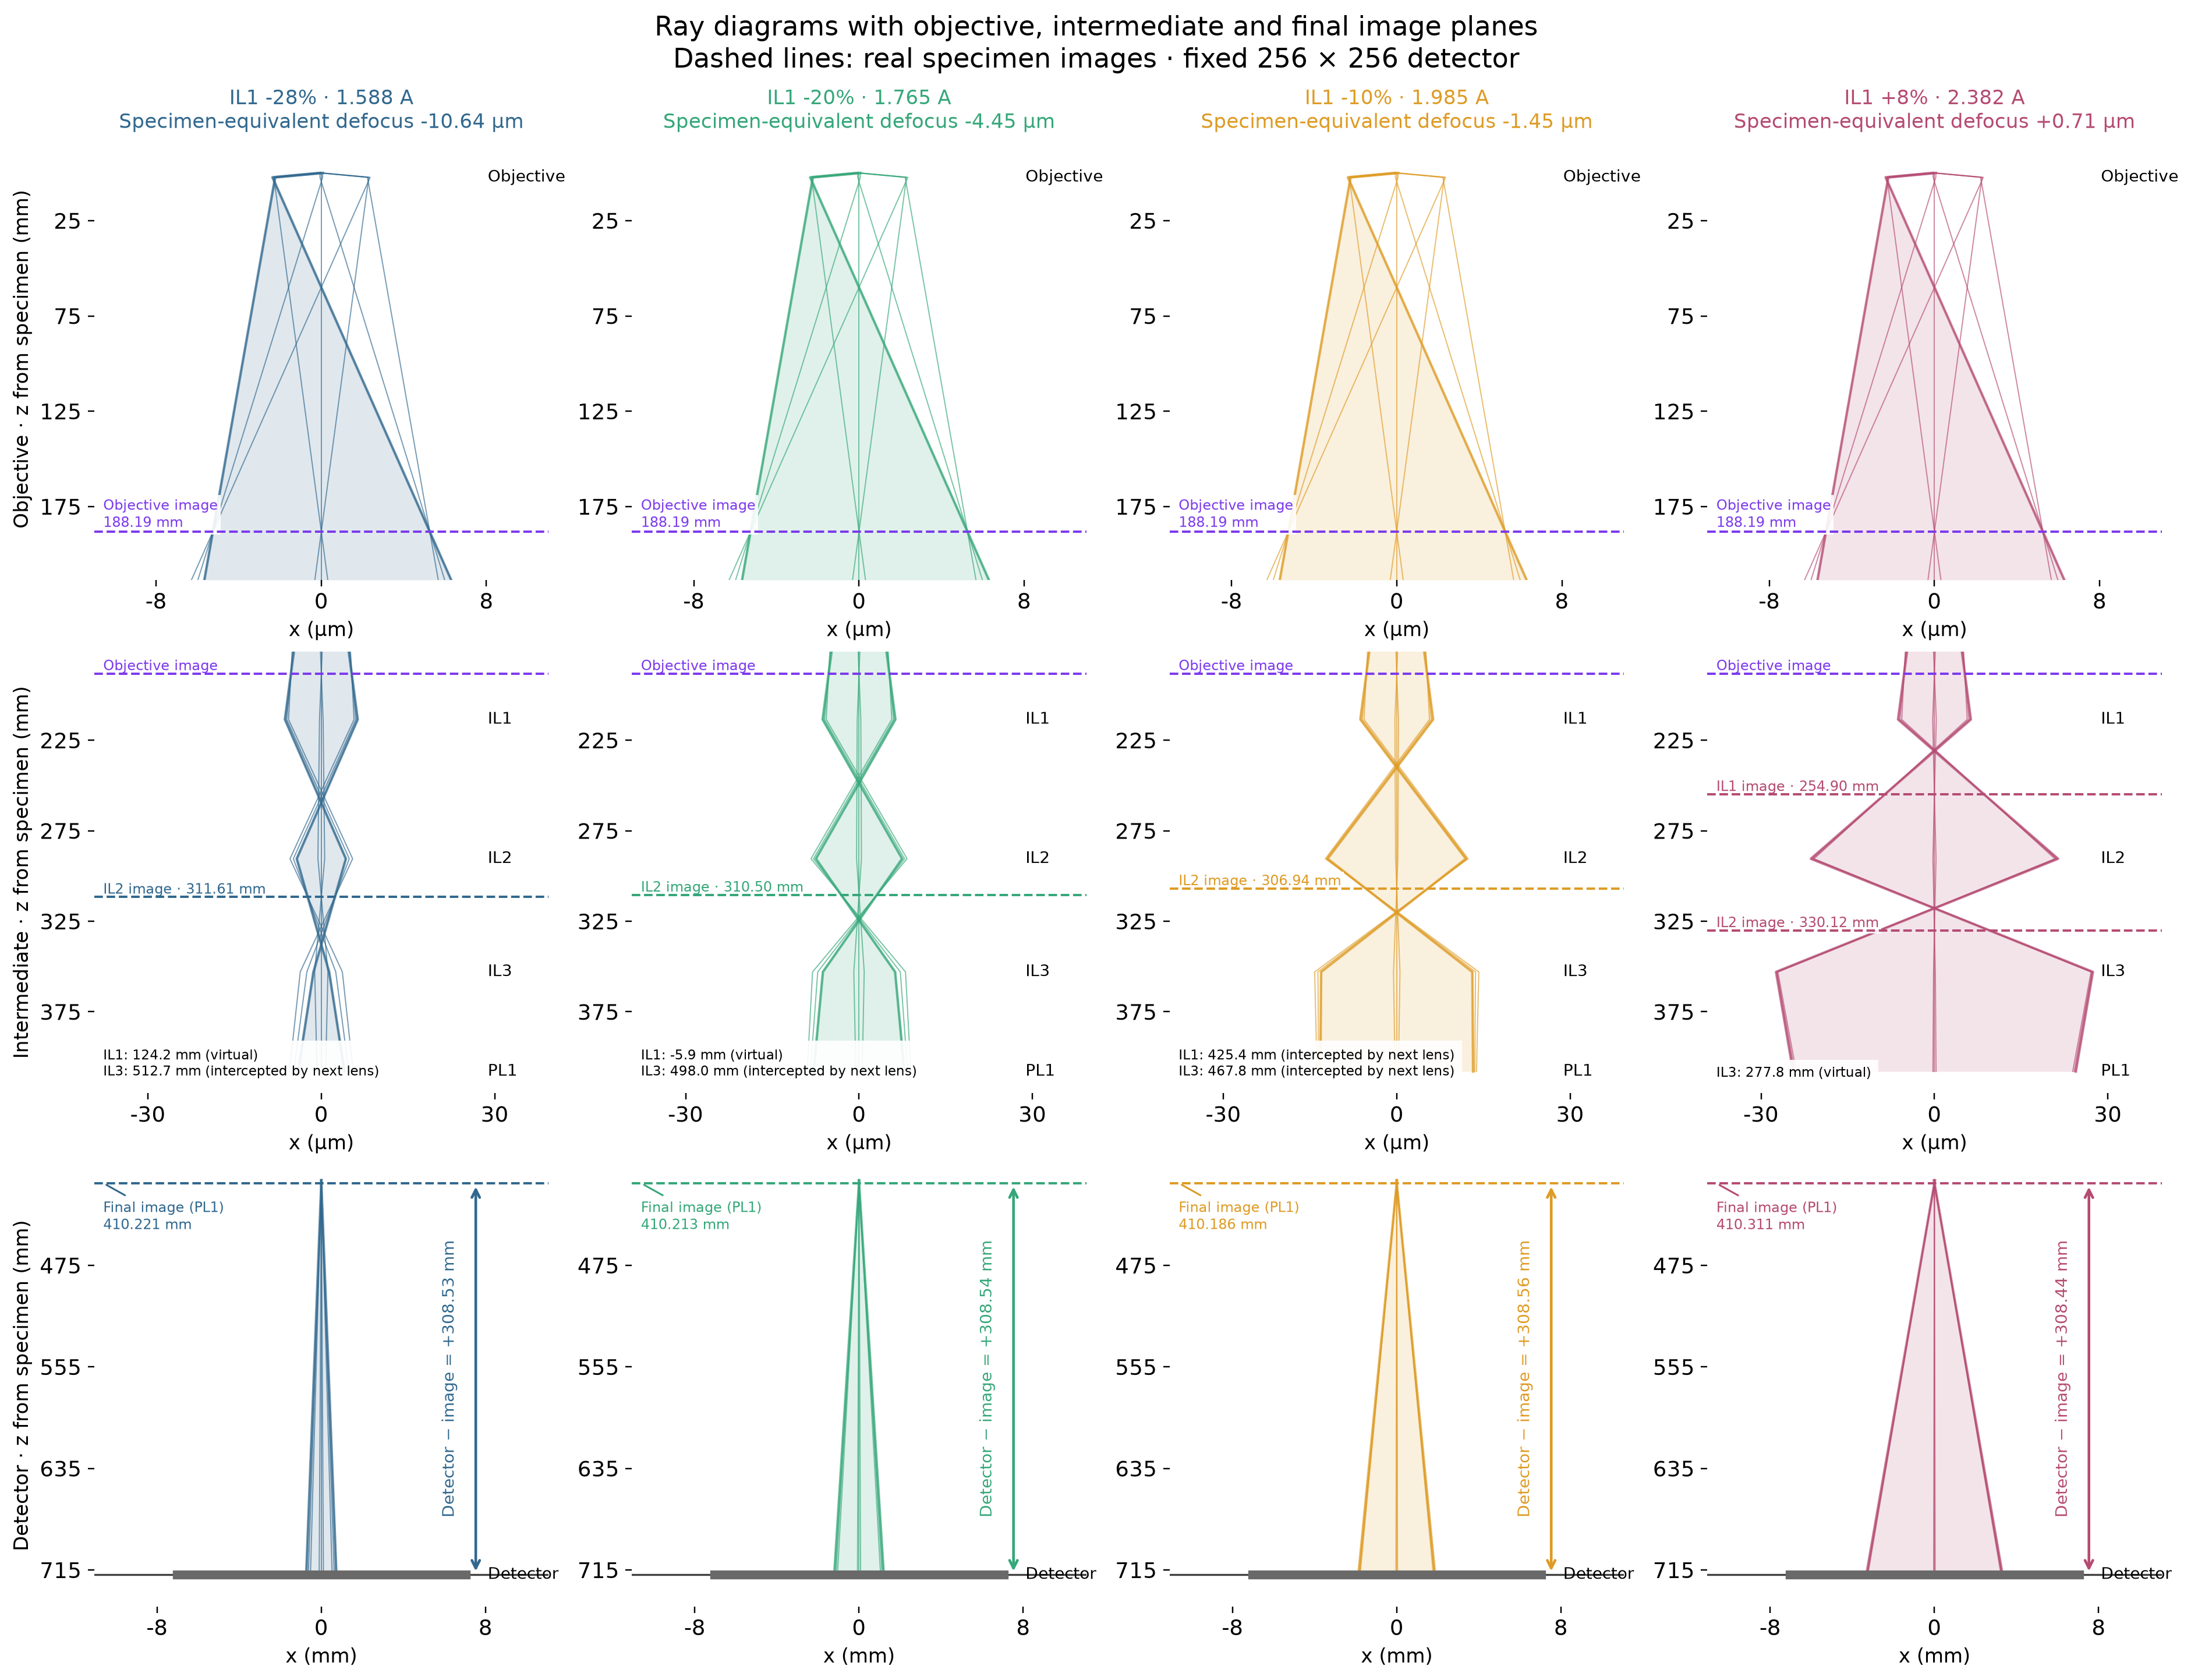

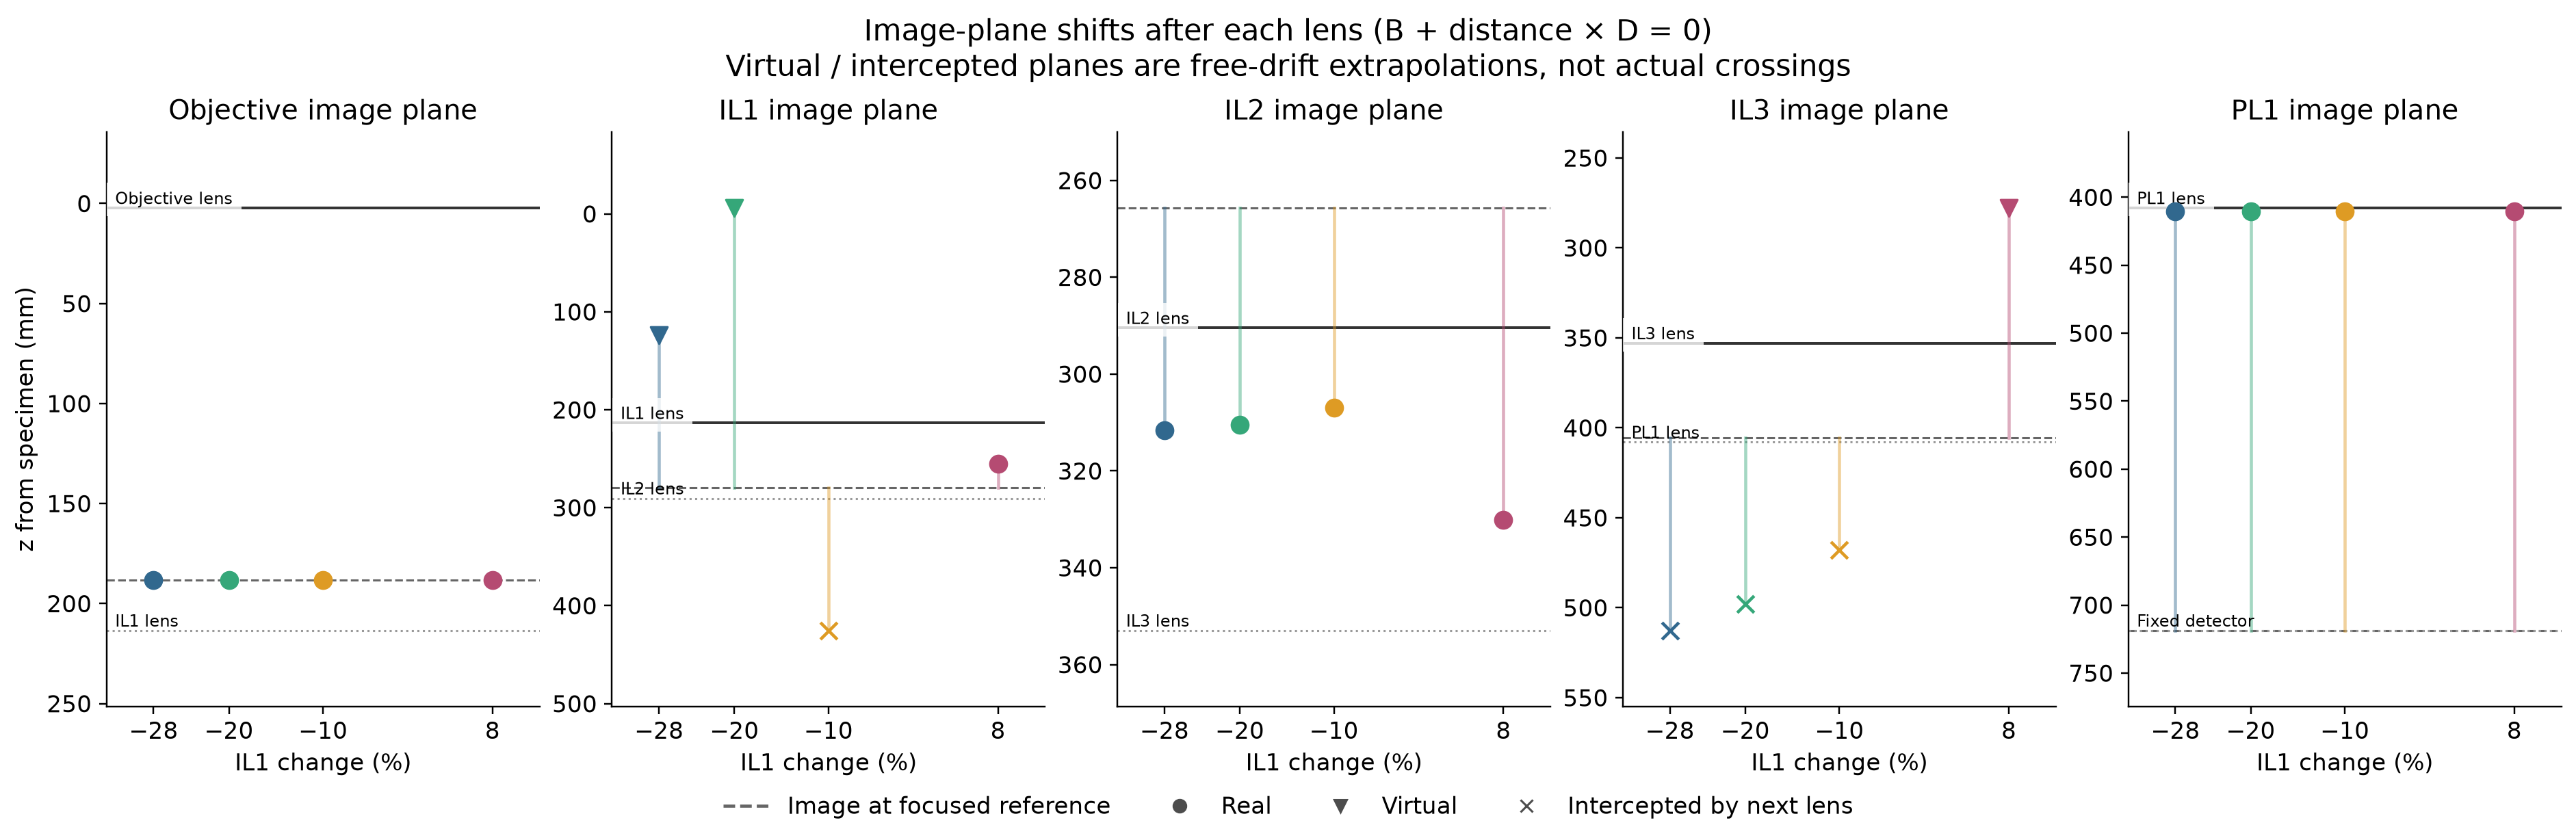

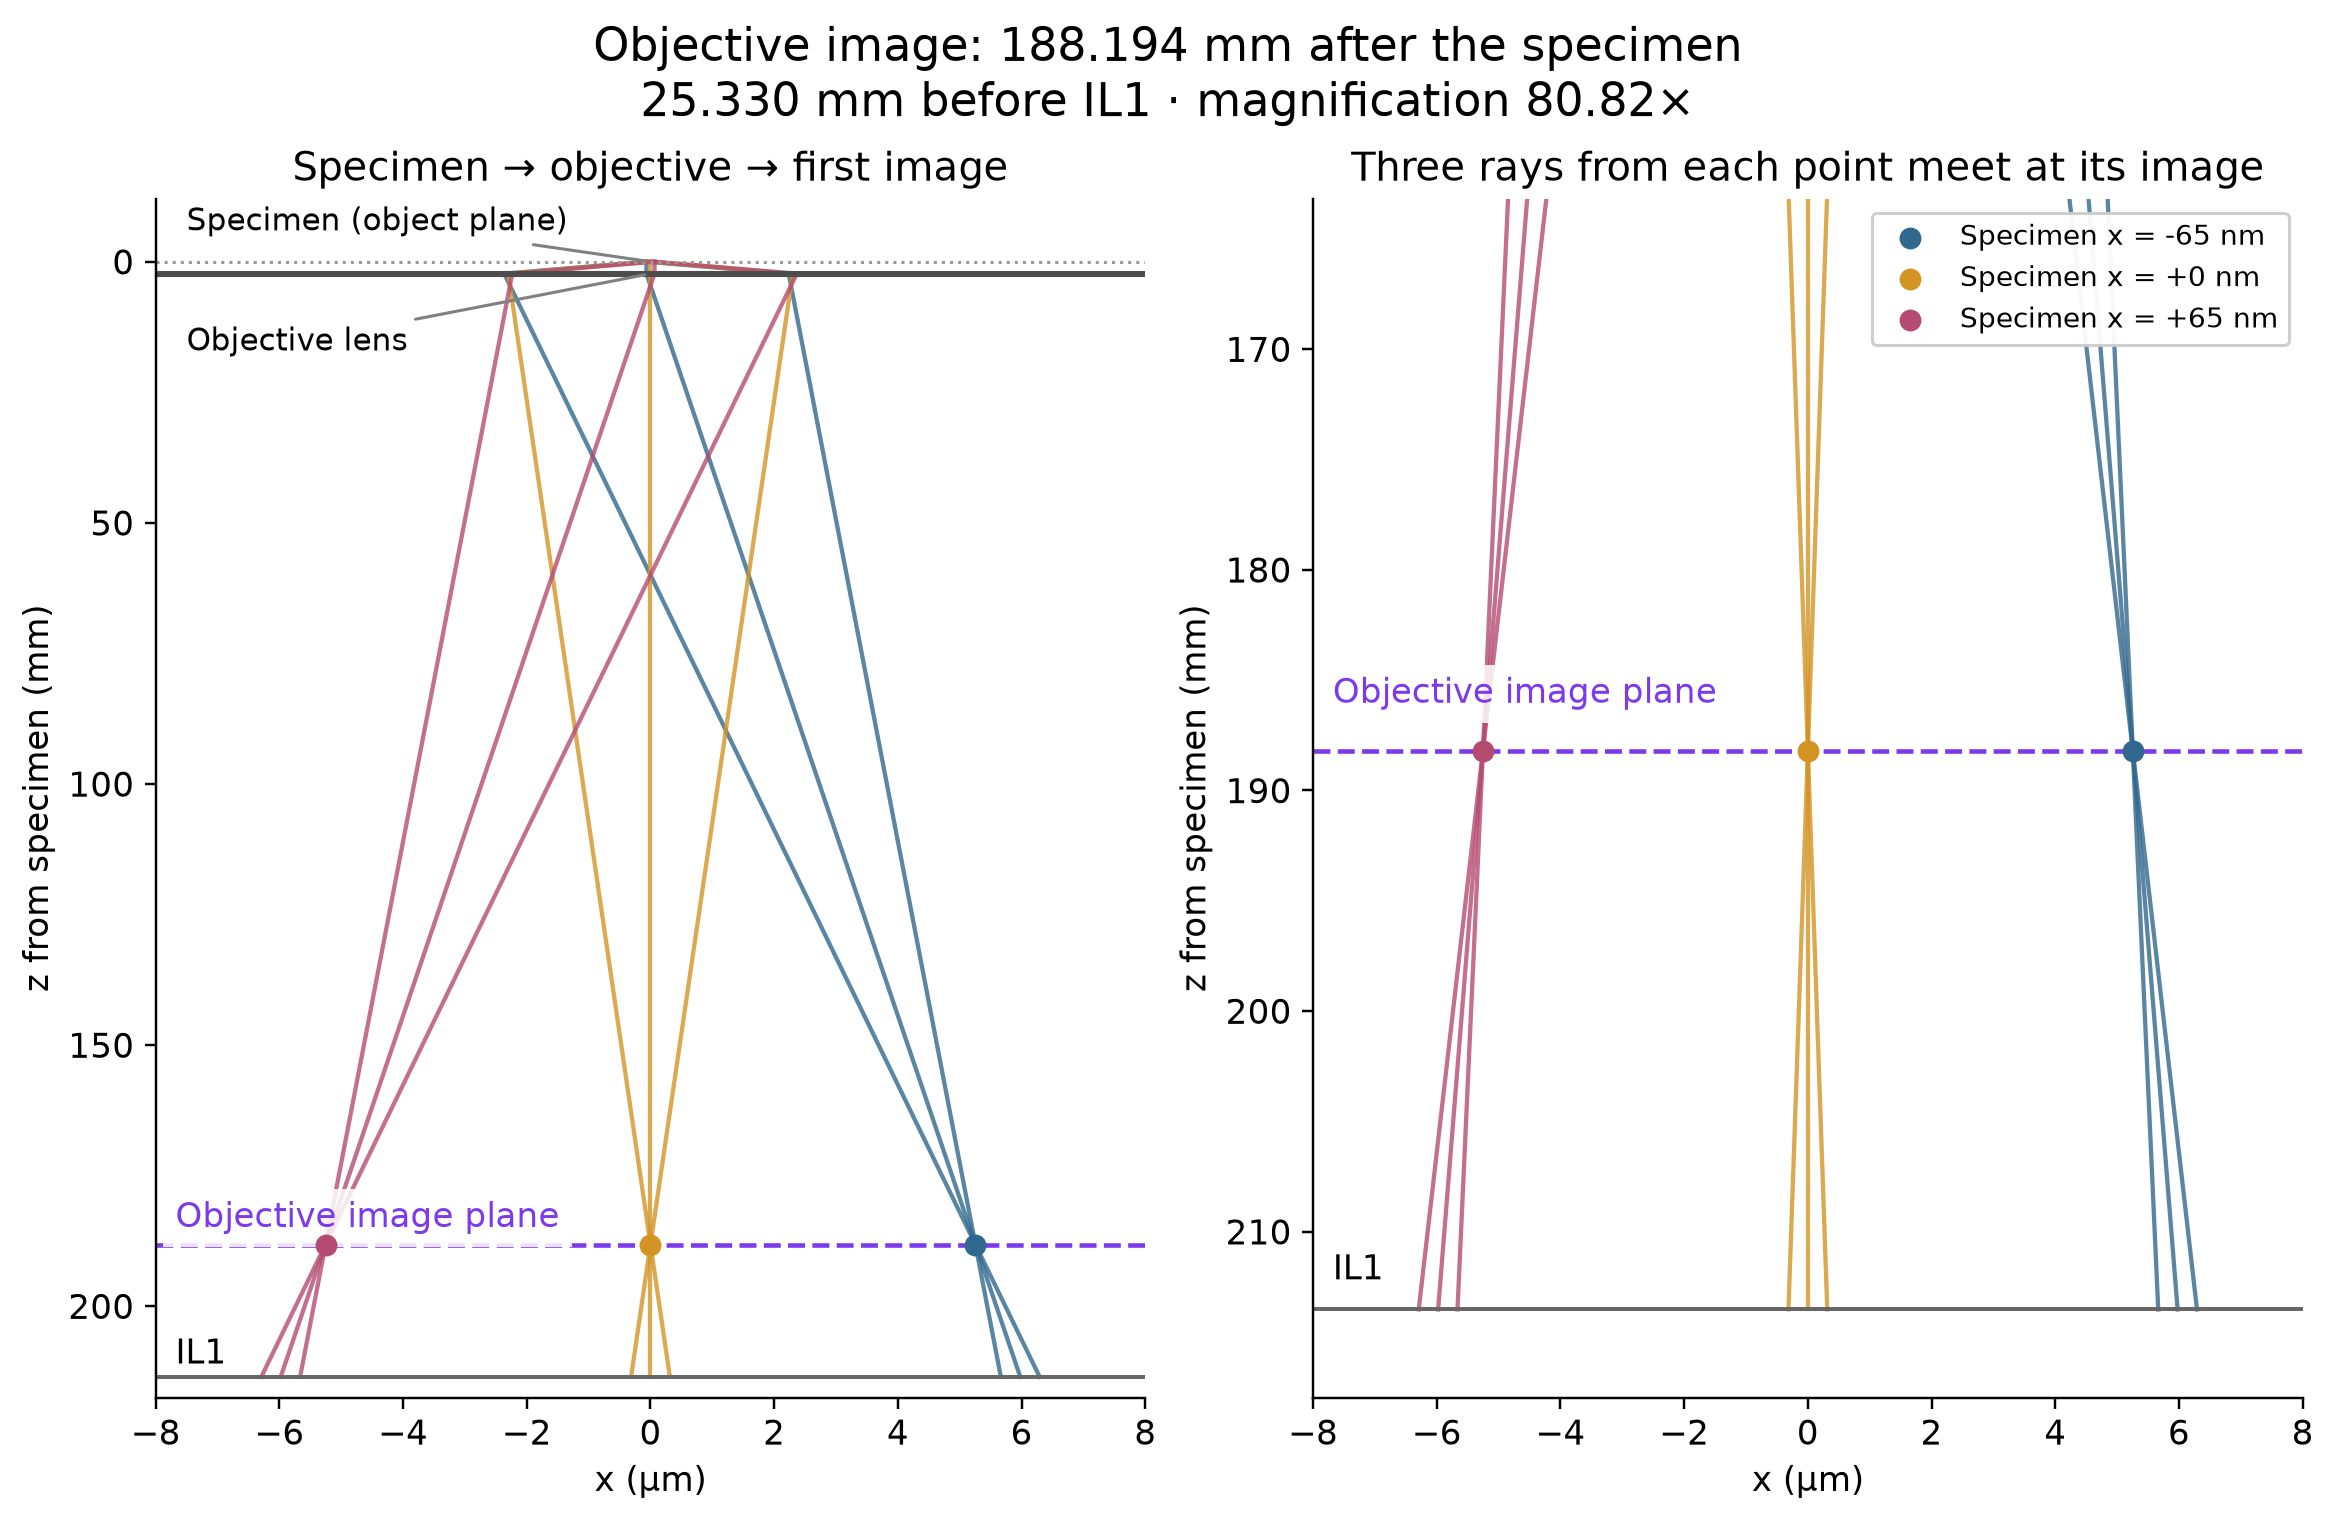

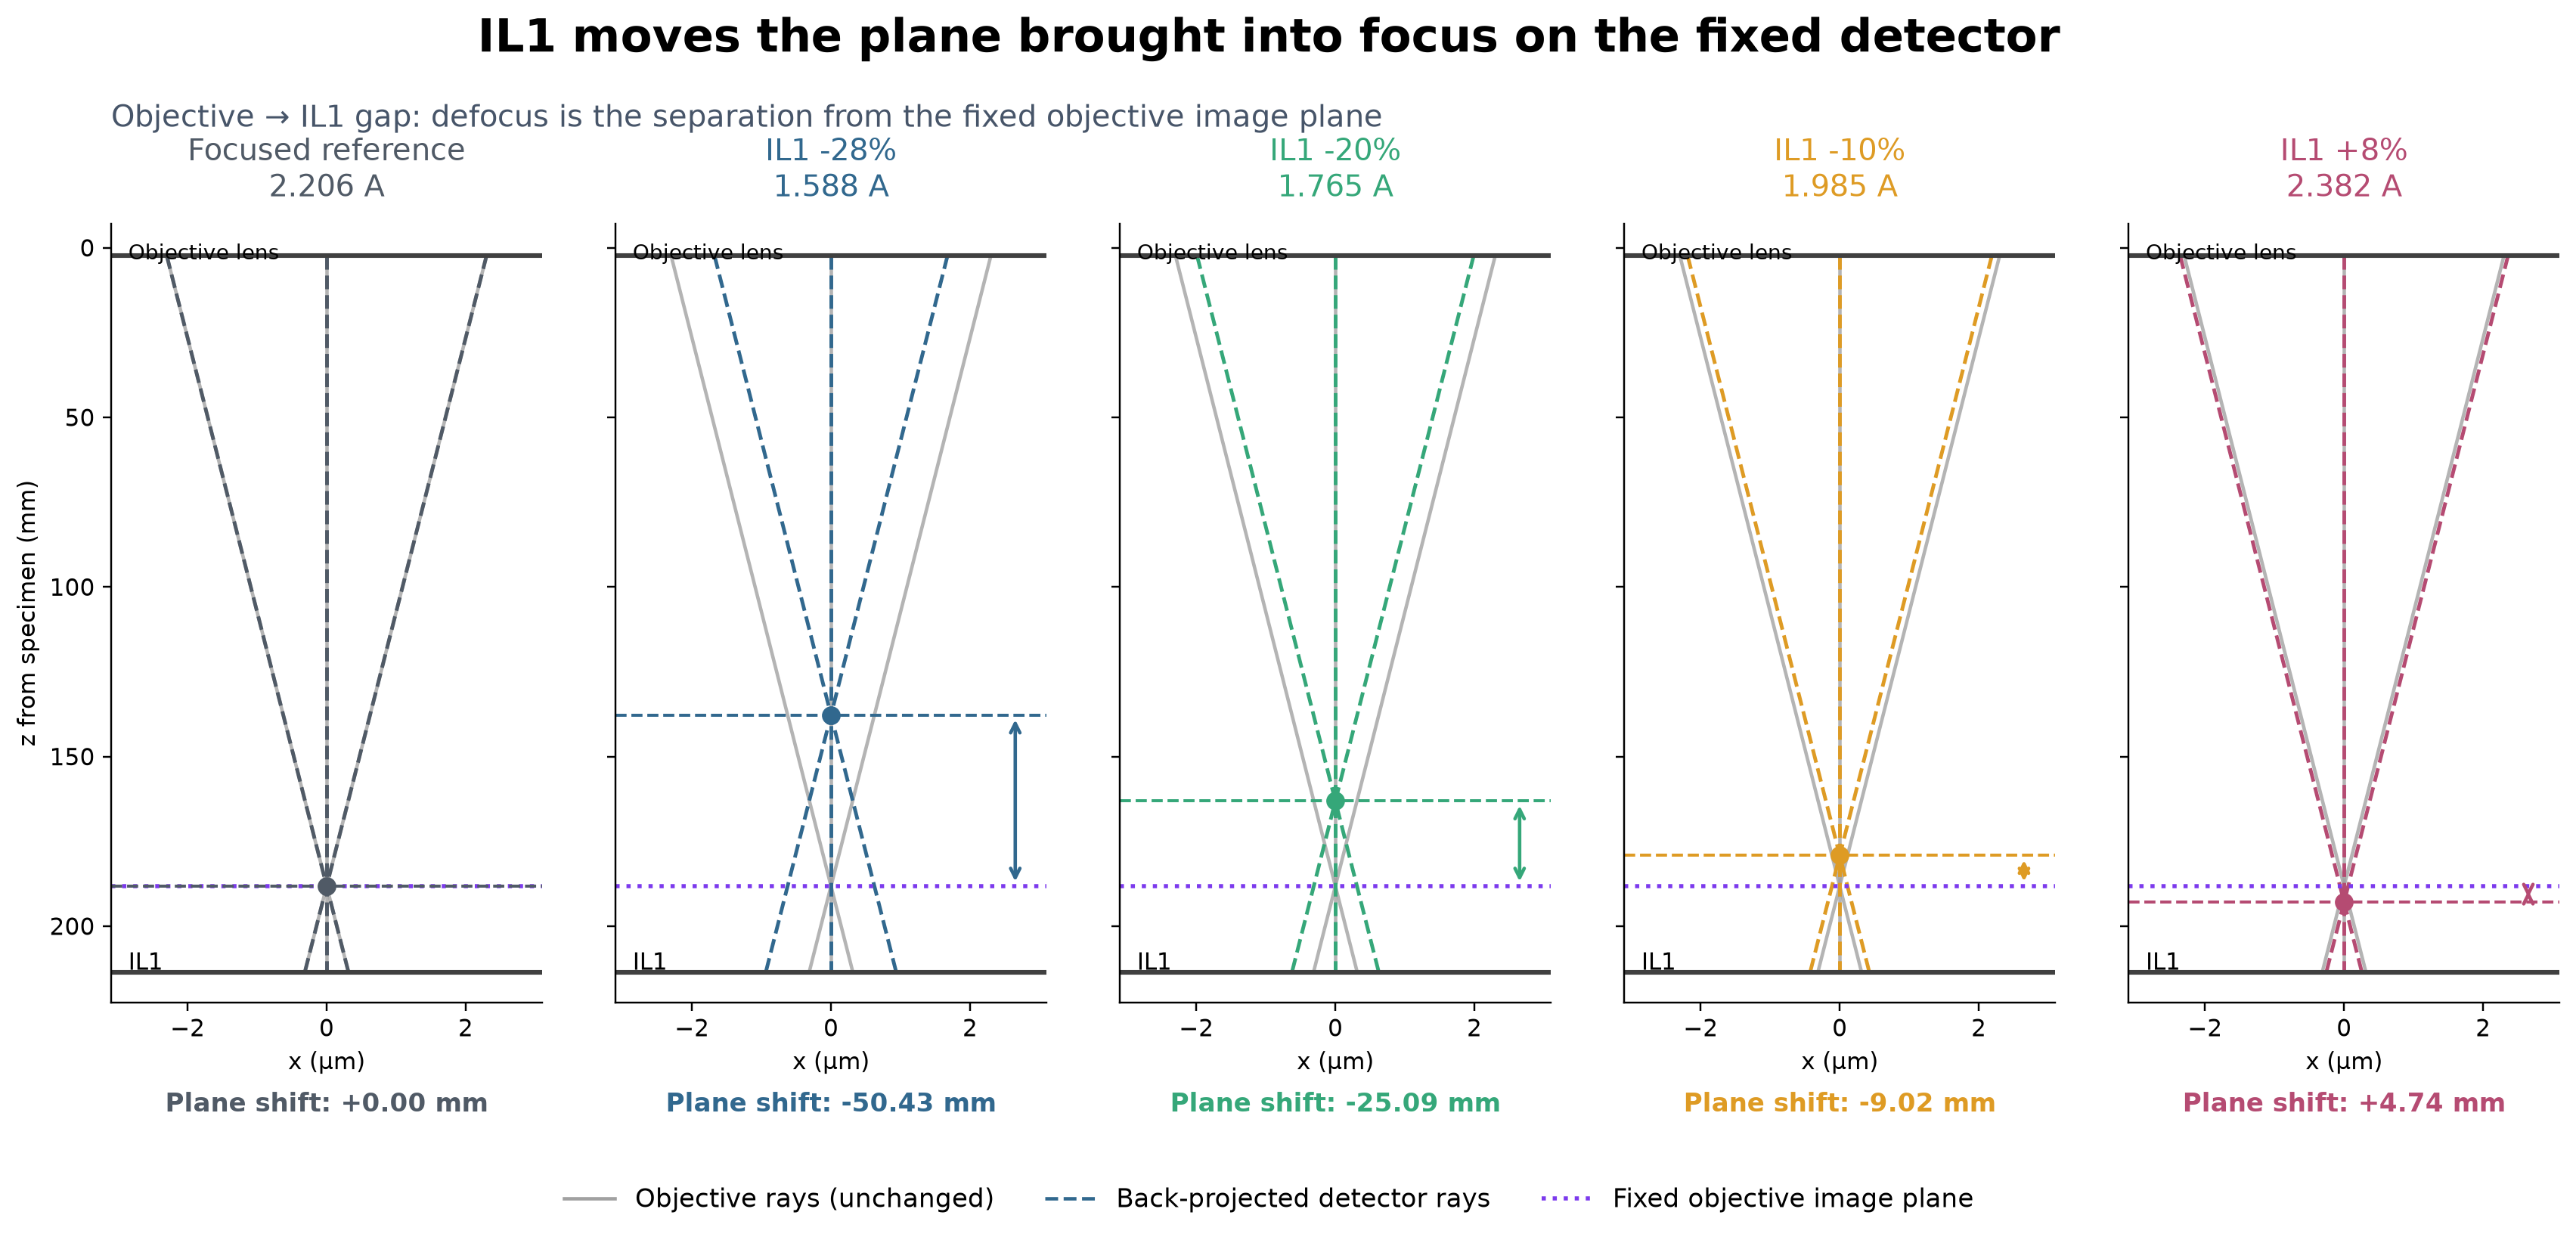

In [2]:
print('IL1 (A)   change   z_eff (µm)     M       rotation (deg)')
for r in calibration['settings']:
    print(f"{r['current_A']:.6f}  {r['delta']:+.0%}    {r['effective_defocus_m']*1e6:+8.3f}   {r['magnification']:7.0f}   {r['rotation_deg']:+7.2f}")
display(Image(filename=str(folder / 'figures/03_native_ray_diagrams.png')))
display(Image(filename=str(folder / 'figures/03b_lens_image_planes.png')))

display(Image(filename=str(folder / 'figures/03c_objective_image_plane.png')))
display(Image(filename=str(folder / 'figures/03d_IL1_object_plane_defocus.png')))

## Four detector images

Noiseless intensities use one fixed **256 × 256, 55 µm-pitch camera** (14.08 mm wide). Display panels crop around each beam and apply the known magnification-squared area factor. The second plot shows intensity divided by the simulated vacuum reference, minus one, on a shared contrast scale. The retrieval uses the original full intensities.

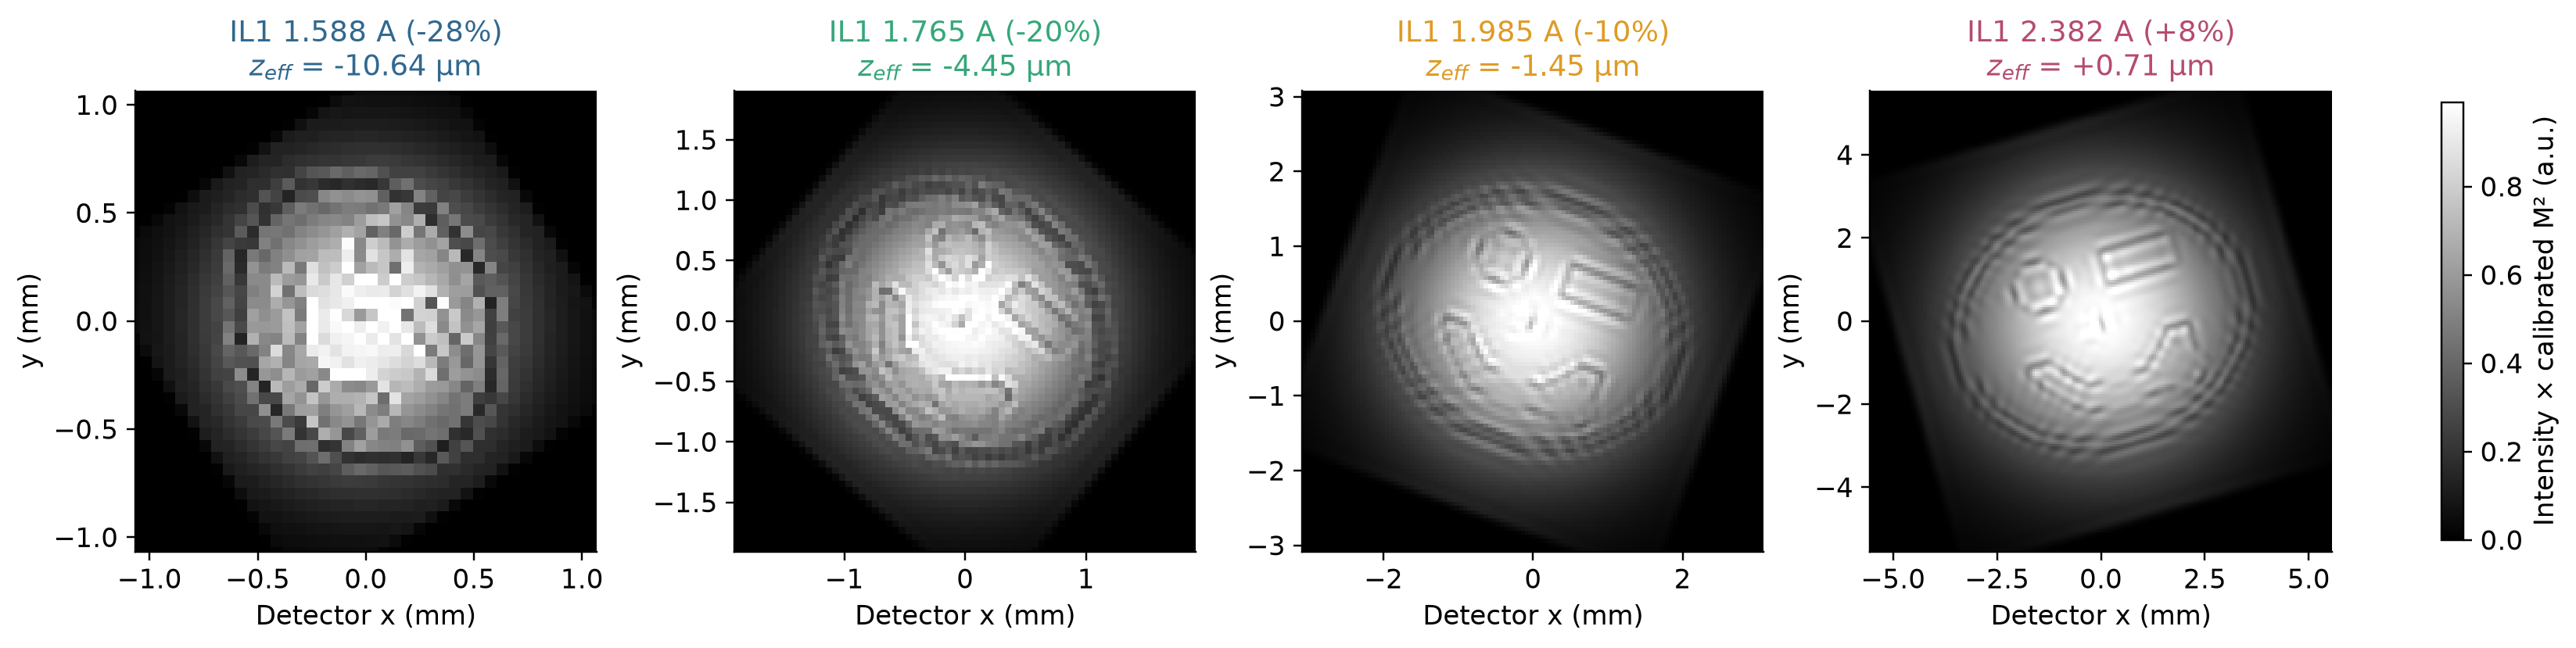

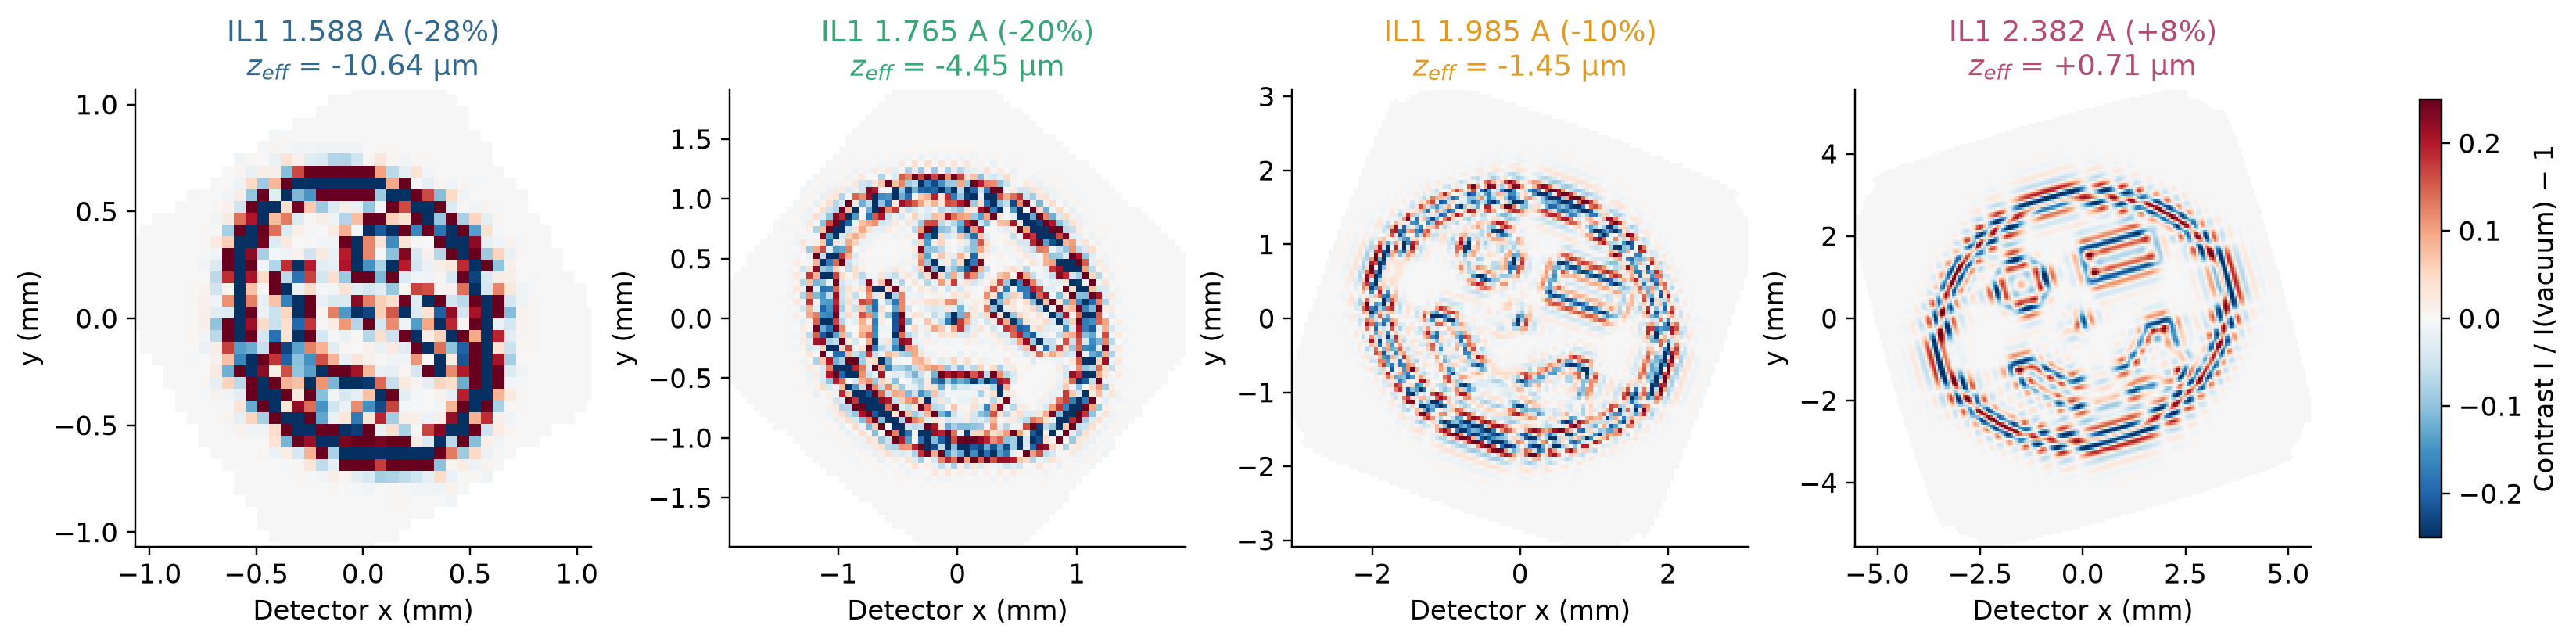

In [3]:
display(Image(filename=str(folder / 'figures/01_detector_defocus_series.png')))
display(Image(filename=str(folder / 'figures/01b_detector_phase_contrast.png')))

## Reconstruct the complex wave

The solver starts from a zero-phase illumination and fits complex Gaussian coefficients using only intensity data and known propagation operators. The true phase is used only to score the result after removing global phase. The comparison deliberately underestimates every IL1 step by 20%.

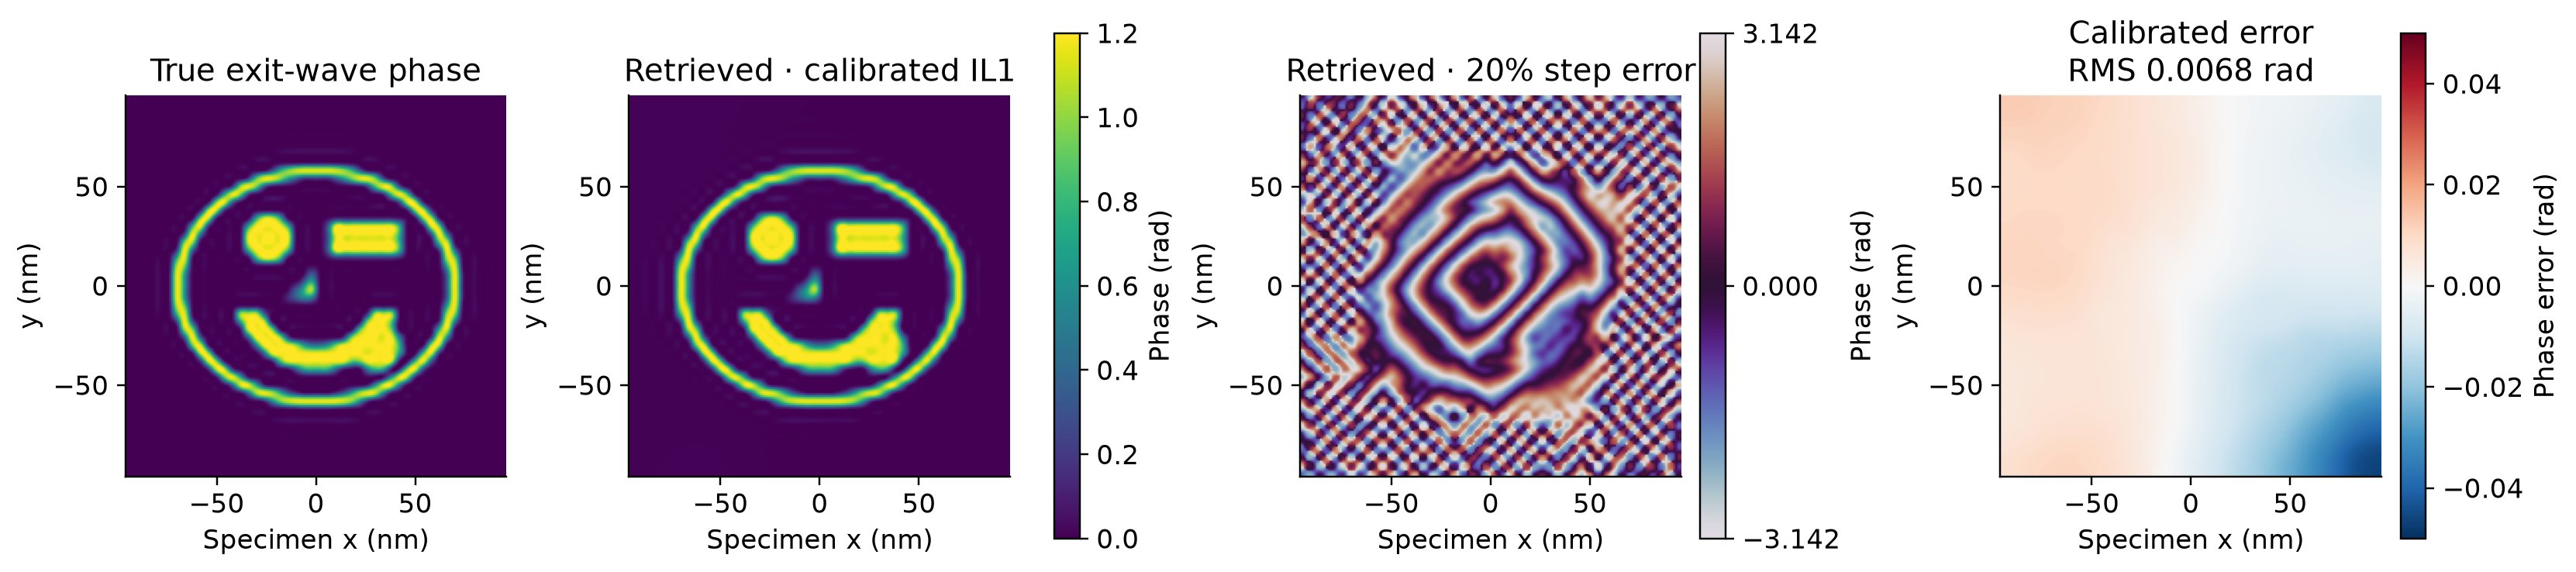

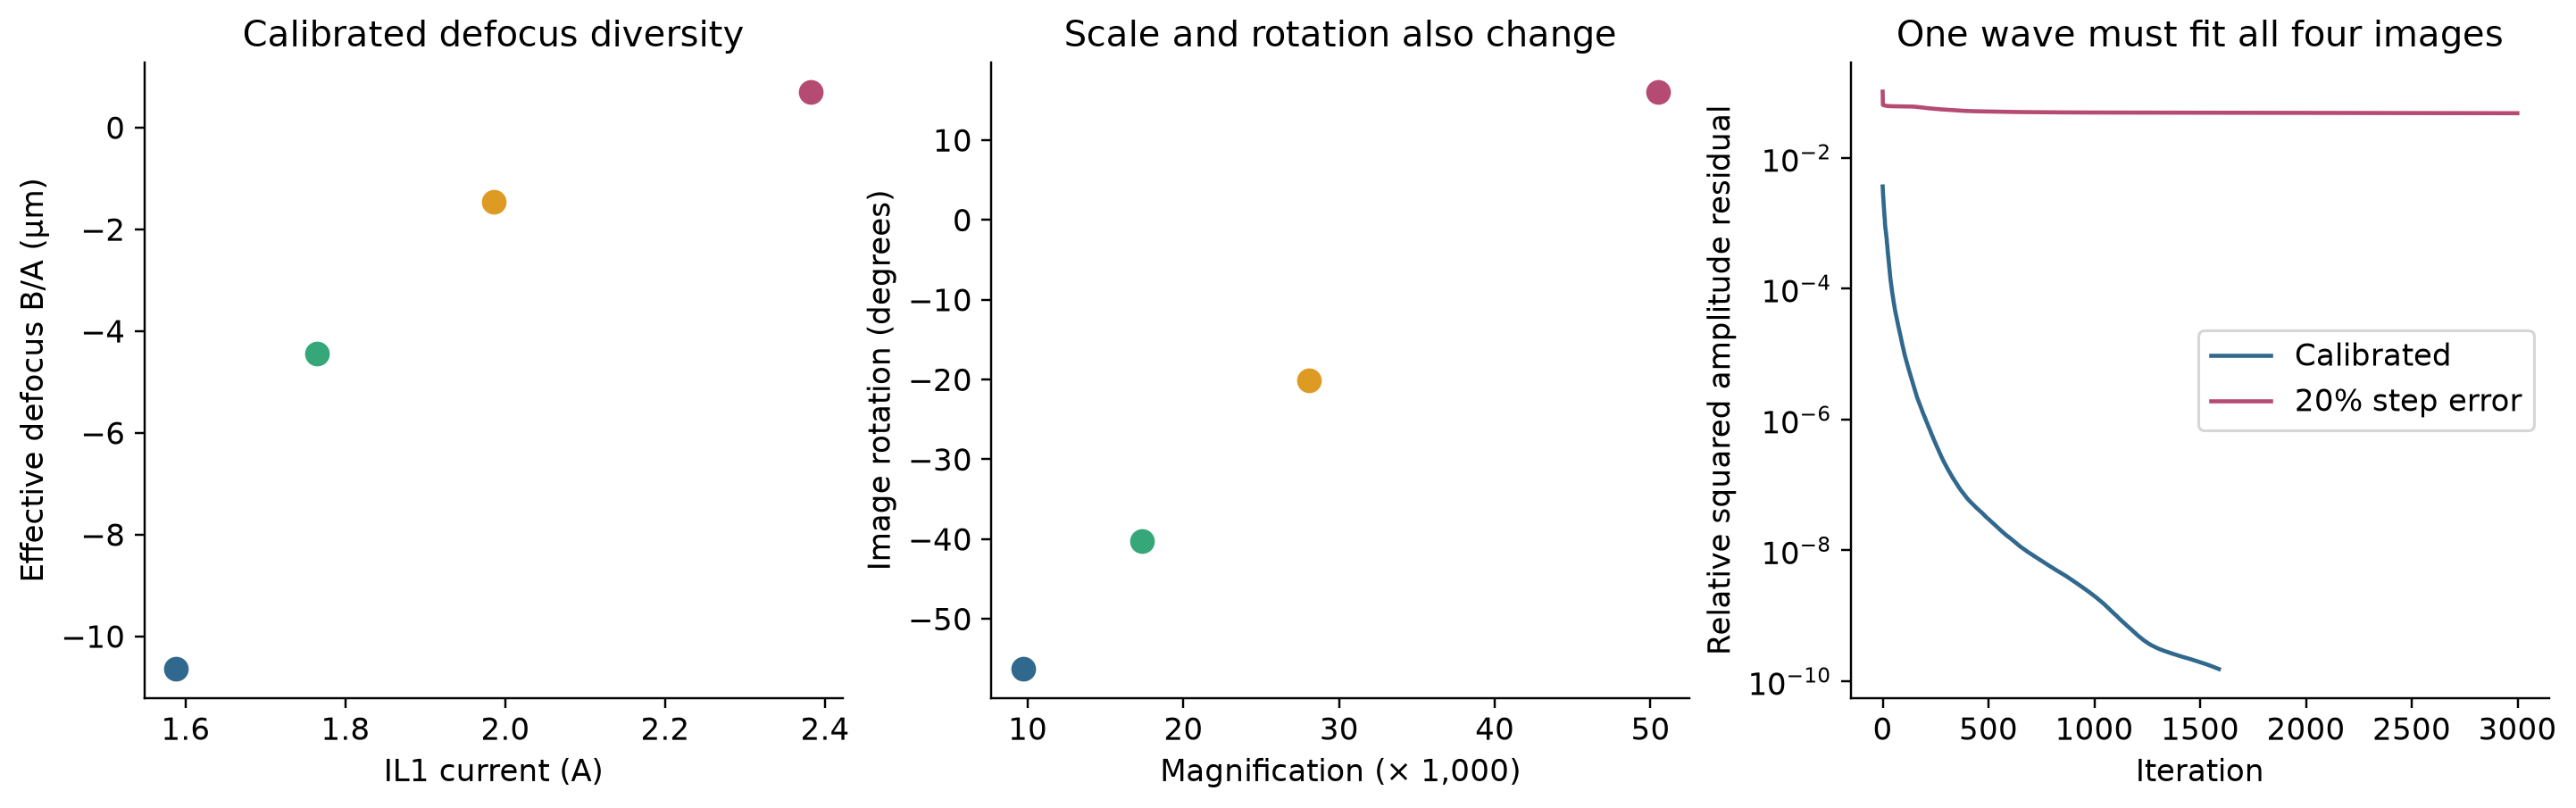

{
  "native_renderer_relative_error": 0.0001035574380617766,
  "phase_rmse_rad": 0.006835619453340769,
  "wrong_calibration_phase_rmse_rad": 1.8031004667282104,
  "complex_wave_relative_error": 0.006125757936388254,
  "calibrated_fit": {
    "loss": 1.5349796433916651e-10,
    "iterations": 1590,
    "converged": true,
    "message": "CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL"
  },
  "wrong_calibration_fit": {
    "loss": 0.04844271391630173,
    "iterations": 3000,
    "converged": false,
    "message": "STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT"
  }
}


In [4]:
display(Image(filename=str(folder / 'figures/02_phase_retrieval.png')))
display(Image(filename=str(folder / 'figures/04_calibration_and_convergence.png')))
print(json.dumps(calibration['metrics'], indent=2))

**Independent prediction check:** the following cell reads the current validation result for an unused IL1 −15% setting, evaluated on the same 256 × 256 camera. Run `verify.py` to repeat this check.

In [5]:
validation = json.loads((folder / 'validation.json').read_text())
print(json.dumps(validation, indent=2))


{
  "held_out_IL1_delta": -0.15,
  "held_out_IL1_current_A": 1.8748261933580812,
  "held_out_intensity_relative_error": 2.274773396550932e-05,
  "detector_shape_yx": [
    256,
    256
  ],
  "checks": "PASS: reference focus, saved calibration, 256\u00d7256 intensities, lens conjugate rays, finite intensities, phase error, unused-setting prediction"
}


## Optional: regenerate

This uses the current kernel environment and writes all outputs into this folder. A GPU is recommended; dense response matrices need several GB of memory.

In [6]:
# Uncomment to rerun the complete forward simulation, retrieval and figure export.
# import subprocess, sys
# subprocess.run([sys.executable, str(folder / 'demonstration.py')], check=True)